# 対象のルートディレクトリを指定
root_dirs = ['dataset/png_256', 'dataset/png_512']

for root_dir in root_dirs:
    for dirpath, dirnames, filenames in os.walk(root_dir):
        # ファイルをすべて削除
        for filename in filenames:
            file_path = os.path.join(dirpath, filename)
            try:
                os.remove(file_path)
                print(f"Deleted: {file_path}")
            except Exception as e:
                print(f"Error deleting {file_path}: {e}")


In [ ]:
from PIL import Image, ImageFile, ImageOps
from patchify import patchify
import os
import numpy as np
import matplotlib.pyplot as plt
import cv2
import glob
from tqdm import tqdm
import random


In [3]:

# Predefined size (already resized to 1536x1536)
imx, imy = (1536, 1536)


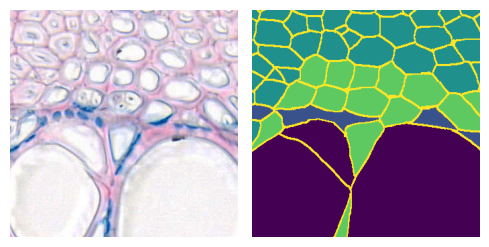

In [4]:

input_dir = 'dataset/original'

# === ファイル取得 ===
msk_paths = sorted(glob.glob(os.path.join(input_dir, 'mask', '*.png')))
img_paths = sorted(glob.glob(os.path.join(input_dir, 'image', '*.png')))

ImageFile.LOAD_TRUNCATED_IMAGES = True

# リサイズなしで画像を読み込む
imgs = [
    Image.open(img_paths[0]),
    Image.open(msk_paths[0])
]

# 表示（例として60〜400pxの範囲をクロップ）
fig, ax = plt.subplots(1, len(imgs), figsize=(5, 10))
for k, img in enumerate(imgs):
    ax[k].imshow(img.crop((60, 60, 400, 400)))
    ax[k].axis('off')
plt.tight_layout()
plt.show()


In [5]:

# チェック対象の値
allowed_values = {0, 64, 128, 192, 255}

for path in msk_paths:
    img = Image.open(path).convert("L")  # グレースケールに変換
    arr = np.array(img)
    unique_values = set(np.unique(arr))

    if not unique_values.issubset(allowed_values):
        print(f"[WARNING] {path} contains unexpected values: {unique_values - allowed_values}")
    else:
        print(f"[OK] {path} contains only expected values.")

[OK] dataset/original/mask/acapod3_01_msk.png contains only expected values.
[OK] dataset/original/mask/acapod3_02_msk.png contains only expected values.
[OK] dataset/original/mask/acapod4_01_msk.png contains only expected values.
[OK] dataset/original/mask/acapod4_02_msk.png contains only expected values.
[OK] dataset/original/mask/alllit3_01_msk.png contains only expected values.
[OK] dataset/original/mask/alllit3_02_msk.png contains only expected values.
[OK] dataset/original/mask/alllit3_03_msk.png contains only expected values.
[OK] dataset/original/mask/alllit6_01_msk.png contains only expected values.
[OK] dataset/original/mask/burspi2_01_msk.png contains only expected values.
[OK] dataset/original/mask/burspi2_02_msk.png contains only expected values.
[OK] dataset/original/mask/burspi2_03_msk.png contains only expected values.
[OK] dataset/original/mask/burspi4_01_msk.png contains only expected values.
[OK] dataset/original/mask/euclon3_01_msk.png contains only expected values.

# 対象となるグレイレベル
valid_values = np.array([0, 64, 128, 192, 255])

# 修正対象のファイル（確認したファイルだけ）
bad_mask_paths = [
    "dataset/original/acapod3_02_msk.png",
    "dataset/original/acapod4_01_msk.png",
    "dataset/original/alllit2_01_msk.png",
    "dataset/original/burspi1_01_msk.png",
    "dataset/original/burspi2_01_msk.png",
    "dataset/original/euclon1_01_msk.png",
    "dataset/original/euclon4_01_msk.png",
    "dataset/original/euclon5_01_msk.png",
    "dataset/original/exostr1_02_msk.png",
    "dataset/original/exostr8_01_msk.png",
]

def round_to_nearest_valid(value_array, valid_vals):
    # value_array: numpy array of mask
    flat = value_array.flatten()
    corrected = np.array([valid_vals[np.argmin(np.abs(valid_vals - v))] for v in flat], dtype=np.uint8)
    return corrected.reshape(value_array.shape)

# 修正＆保存
for path in bad_mask_paths:
    img = Image.open(path).convert("L")
    arr = np.array(img)
    fixed_arr = round_to_nearest_valid(arr, valid_values)

    # 保存（上書き）
    Image.fromarray(fixed_arr).save(path)
    print(f"Fixed and saved: {path}")


In [6]:
# === PIL形式で読み込み ===
masks_pil = [Image.open(p) for p in msk_paths]
images_pil = [Image.open(p) for p in img_paths]
print("mask files:", len(masks_pil))
print("original files:", len(images_pil))

mask files: 24
original files: 24


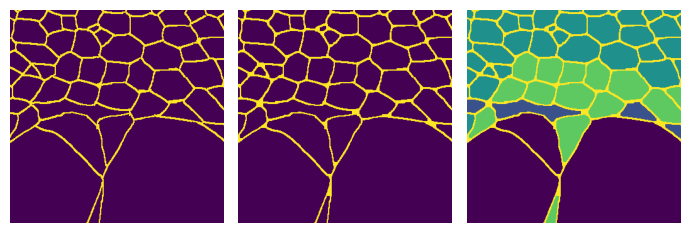

In [7]:
# mask was slightly modified by binary treatement such as dilation and erosion.

# === 関数定義 ===

def binarize_mask(mask):
    binary_mask = np.where(mask > 230, 255, 0).astype(np.uint8) ###  == -> >
    return binary_mask

def thicken_binary(mask_binary):
    kernel = np.ones((3, 3), np.uint8)  # 3x3カーネル
    thick_binary = cv2.dilate(mask_binary, kernel, iterations=2) 
    thick_binary = cv2.erode(thick_binary, kernel, iterations=2) #thin patchを作って試してみる
    #thick_binary = cv2.erode(thick_binary, kernel, iterations=1) オリジナルではこっち　
    #thick_binary = cv2.dilate(mask_binary, kernel, iterations=1) # 境界を膨張させる    
    # 膨張した部分をグレイレベル255に設定
    thick_binary[thick_binary > 0] = 255    
    return thick_binary

def overlay_thick_on_mask(original_mask, thick_binary):
    thick_mask = np.where(thick_binary == 255, 255, original_mask)  # オーバーレイ
    return thick_mask

bimg = binarize_mask(np.array(imgs[1]))
t_bimg = thicken_binary(bimg)
#t_mask = overlay_thick_on_mask(imgs[1],t_bimg)
t_mask = overlay_thick_on_mask(np.array(imgs[1]), t_bimg)


msks = [bimg,t_bimg,t_mask]

fig, ax = plt.subplots(1,len(msks),figsize=(7,15))
for k, msk in enumerate(msks):
    #x[k].imshow(msk.crop((60, 60, 400, 400)))
    ax[k].imshow(msk[60:400,60:400])
    ax[k].axis('off')
plt.tight_layout()
plt.show()


#### Check gray-level
#### 

In [8]:
np.unique(t_bimg)

array([  0, 255], dtype=uint8)

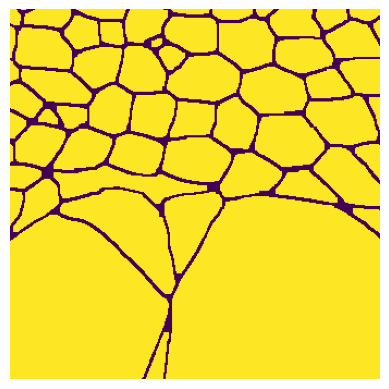

In [9]:

tmp_mask = Image.fromarray(t_bimg)
new_mask = ImageOps.invert(tmp_mask)

plt.imshow(new_mask.crop((60, 60, 400, 400)))
plt.axis('off')
plt.show()


###  File allocations

In [10]:
# Now I make new directories for dataset for mask-RCNN
# === 乱数で train/valid/test に分割 ===
def rand_order(num):
    import random
    r = set(range(num))
    x = set(random.sample(range(0, num), k=int(num * 0.6)))
    y = set(random.sample(list(r - x), k=int((num - len(x)) * 0.6)))
    z = list(r - x - y)
    return [list(x), list(y), z]

# === 保存先ディレクトリの作成 ===
for key_1 in [256, 512]:
    for key_2 in ['train', 'valid', 'test']:
        img_dir = f"dataset/png_{key_1}/image/{key_2}/"
        msk_dir = f"dataset/png_{key_1}/mask/{key_2}/"
        os.makedirs(img_dir, exist_ok=True)
        os.makedirs(msk_dir, exist_ok=True)

# === パッチ作成＆保存 ===
for i in range(len(img_paths)):
    save_index = "_" + os.path.splitext(os.path.basename(img_paths[i]))[0]

    img = Image.open(img_paths[i]).resize((imy, imx))
    msk = Image.open(msk_paths[i]).resize((imy, imx))
    imgs = [img, msk]

    # --- 前処理 ---
    bimg = binarize_mask(np.array(imgs[1]))
    t_bimg = thicken_binary(bimg)
    t_mask = overlay_thick_on_mask(imgs[1], t_bimg)
    tmp_mask = Image.fromarray(t_mask).convert("L")
    new_mask = ImageOps.invert(tmp_mask)

    # --- パッチ化と保存 ---
    for key_1 in [256, 512]:
        patches_1 = patchify(np.array(imgs[0])[:,:,:3], (key_1, key_1, 3), step=key_1)
        patches_go_1 = patches_1.reshape((-1, key_1, key_1, 3))

        patches_2 = patchify(np.array(new_mask), (key_1, key_1), step=key_1)
        patches_go_2 = patches_2.reshape((-1, key_1, key_1))

        imgs_num = int(imx / key_1) * int(imy / key_1)
        flist = rand_order(imgs_num)

        for k, key_2 in enumerate(['train','valid', 'test']):
            for j in flist[k]:
                img_f_1 = Image.fromarray(patches_go_1[j]).convert('RGB')
                img_dir = f"dataset/png_{key_1}/image/{key_2}/"
                img_f_1.save(os.path.join(img_dir, f'{j:04}{save_index}.png'))

                img_f_2 = Image.fromarray(patches_go_2[j]).convert('L')
                msk_dir = f"dataset/png_{key_1}/mask/{key_2}/"
                img_f_2.save(os.path.join(msk_dir, f'{j:04}{save_index}.png'))


The end of script

In [11]:
np.array(new_mask).shape

(1536, 1536)

### Data preparation for building Mask-RCNN
- step1 : remake boundary thickend mask
- step2 : make

